In [1]:

from pathlib import Path
import platform
import torch

# 1. Dataset directory
DATA_DIR = Path.cwd()

print("Dataset directory:", DATA_DIR)

# 2. Verify the dataset structure
for name in ["Brittle", "Ductile", "Mixed", "Labels.csv"]:
    path = DATA_DIR / name
    print(f"{name}: {'Found' if path.exists() else 'NOT FOUND'}")

# 3. Check hardware and PyTorch
print("\nSystem:", platform.platform())
print("PyTorch version:", torch.__version__)

# 4. Select the best available device
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Training device:", DEVICE)


Dataset directory: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database
Brittle: Found
Ductile: Found
Mixed: Found
Labels.csv: Found

System: macOS-26.6.2-arm64-arm-64bit-Mach-O
PyTorch version: 2.15.0
Training device: mps


In [2]:

import csv
from collections import Counter

# 1. Read the CSV
csv_path = DATA_DIR / "Labels.csv"

with open(csv_path, "r", encoding="utf-8-sig") as f:
    rows = list(csv.DictReader(f))

print("Total CSV records:", len(rows))
print("First 5 records:", rows[:5])

# 2. Keep valid image records
CLASSES = ["Brittle", "Ductile", "Mixed"]

records = [
    row for row in rows
    if row["label"] in CLASSES
    and row["filename"].lower().endswith(".png")
]

print("\nValid image records:", len(records))
print("Excluded records:", len(rows) - len(records))

# 3. Class distribution
class_counts = Counter(row["label"] for row in records)

print("\nClass distribution:")
for label in CLASSES:
    count = class_counts[label]
    percentage = count / len(records) * 100
    print(f"{label}: {count} images ({percentage:.2f}%)")

# 4. Verify corresponding image files exist
missing = [
    row["filename"] for row in records
    if not (DATA_DIR / row["label"] / row["filename"]).is_file()
]

print("\nMissing image files:", len(missing))
print("Examples:", missing[:5])

# 5. Check duplicate filenames
filenames = [row["filename"] for row in records]
print("Duplicate filenames:",
      len(filenames) - len(set(filenames)))


Total CSV records: 1962
First 5 records: [{'filename': '100Cr6_AR_05_11.png', 'label': 'Brittle'}, {'filename': '100Cr6_AR_05_17.png', 'label': 'Brittle'}, {'filename': '100Cr6_AR_05_18.png', 'label': 'Brittle'}, {'filename': '100Cr6_AR_05_25.png', 'label': 'Brittle'}, {'filename': '100Cr6_AR_06_10.png', 'label': 'Brittle'}]

Valid image records: 1961
Excluded records: 1

Class distribution:
Brittle: 822 images (41.92%)
Ductile: 996 images (50.79%)
Mixed: 143 images (7.29%)

Missing image files: 0
Examples: []
Duplicate filenames: 0


Image dimensions:
  (500, 500): 1961 images

Image color modes:
  L: 1961 images


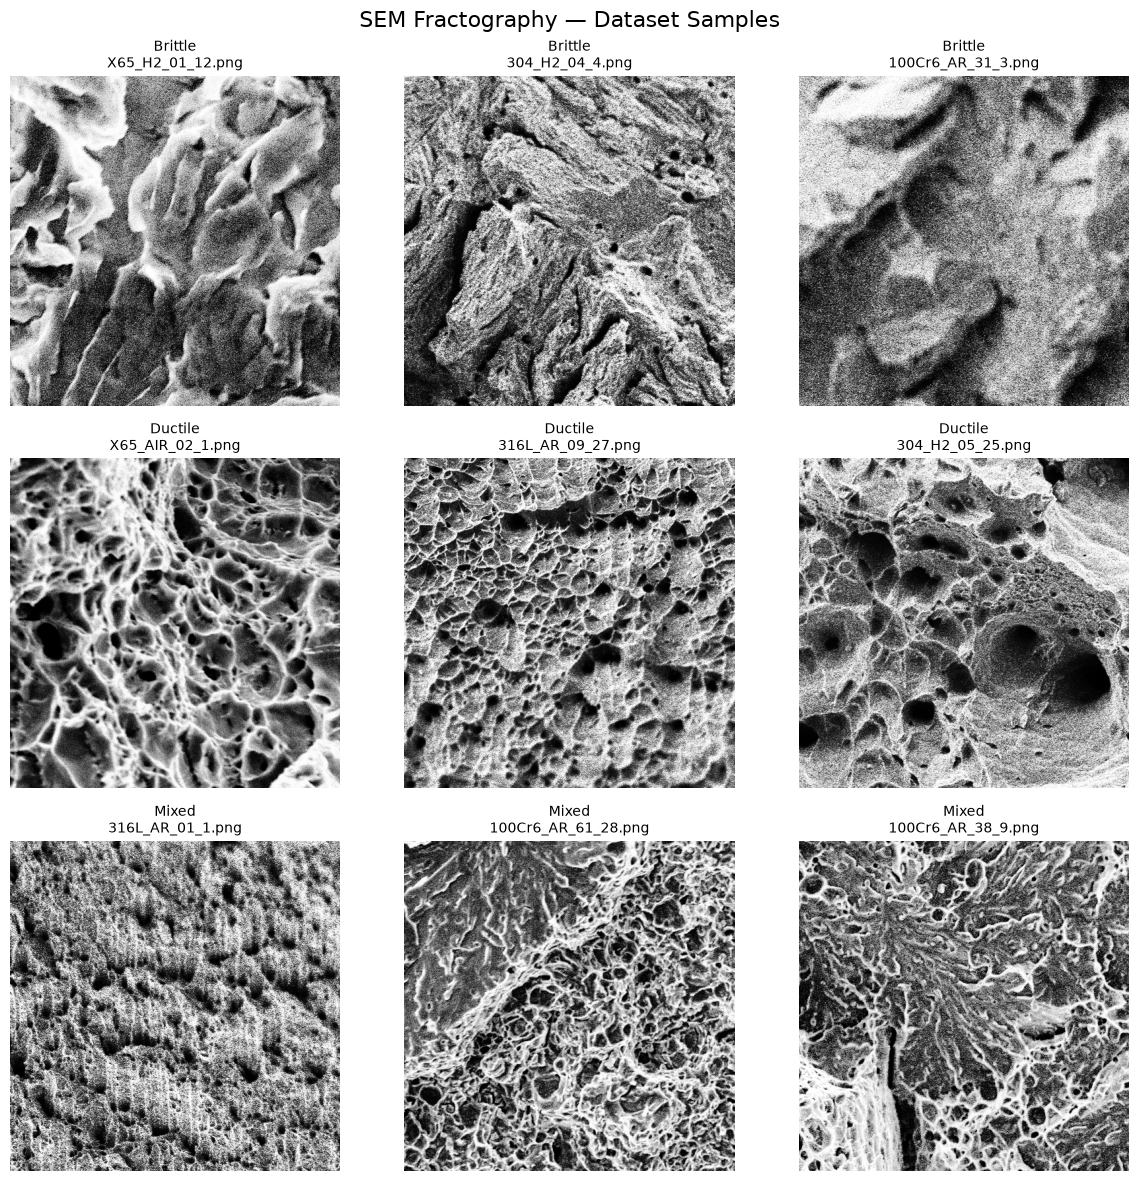

In [3]:

from PIL import Image
import matplotlib.pyplot as plt
import random

# 1. Check image dimensions and formats
image_sizes = Counter()
image_modes = Counter()

for row in records:
    image_path = DATA_DIR / row["label"] / row["filename"]

    with Image.open(image_path) as img:
        image_sizes[img.size] += 1
        image_modes[img.mode] += 1

print("Image dimensions:")
for size, count in image_sizes.most_common():
    print(f"  {size}: {count} images")

print("\nImage color modes:")
for mode, count in image_modes.most_common():
    print(f"  {mode}: {count} images")

# 2. Select 3 random images per class
rng = random.Random(42)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row_idx, label in enumerate(CLASSES):

    class_records = [
        row for row in records if row["label"] == label
    ]

    samples = rng.sample(class_records, 3)

    for col_idx, sample in enumerate(samples):

        image_path = (
            DATA_DIR / label / sample["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("L")

        ax = axes[row_idx, col_idx]
        ax.imshow(image, cmap="gray")
        ax.set_title(
            f"{label}\n{sample['filename']}",
            fontsize=10
        )
        ax.axis("off")

plt.suptitle("SEM Fractography — Dataset Samples", fontsize=16)
plt.tight_layout()
plt.show()


In [4]:

from collections import defaultdict, Counter
from statistics import median
from pathlib import Path

# 1. Extract a provisional group ID from each filename
def get_group_id(filename):
    stem = Path(filename).stem
    return stem.rsplit("_", 1)[0]

# 2. Organize images by group
groups = defaultdict(list)

for row in records:
    group_id = get_group_id(row["filename"])
    groups[group_id].append(row)

# 3. Analyze group sizes
group_sizes = [len(images) for images in groups.values()]

print("Total images:", len(records))
print("Number of groups:", len(groups))
print("Smallest group:", min(group_sizes), "images")
print("Largest group:", max(group_sizes), "images")
print("Median group size:", median(group_sizes))

# 4. Examine class labels within each group
group_labels = {
    group_id: Counter(row["label"] for row in images)
    for group_id, images in groups.items()
}

print("\nNumber of groups containing each class:")

for label in CLASSES:
    count = sum(
        label in labels
        for labels in group_labels.values()
    )
    print(f"{label}: {count} groups")

# 5. Find groups containing more than one class
multi_class_groups = {
    group_id: labels
    for group_id, labels in group_labels.items()
    if len(labels) > 1
}

print("\nGroups containing multiple classes:",
      len(multi_class_groups))

for group_id, labels in list(multi_class_groups.items())[:10]:
    print(group_id, dict(labels))

# 6. Show the 10 largest groups
print("\n10 largest groups:")

largest_groups = sorted(
    groups.items(),
    key=lambda item: len(item[1]),
    reverse=True
)[:10]

for group_id, images in largest_groups:
    print(
        f"{group_id}: {len(images)} images | "
        f"{dict(group_labels[group_id])}"
    )


Total images: 1961
Number of groups: 206
Smallest group: 1 images
Largest group: 26 images
Median group size: 8.0

Number of groups containing each class:
Brittle: 88 groups
Ductile: 136 groups
Mixed: 53 groups

Groups containing multiple classes: 54
100Cr6_AR_05 {'Brittle': 4, 'Ductile': 1}
100Cr6_AR_19 {'Brittle': 5, 'Mixed': 1}
100Cr6_AR_28 {'Brittle': 5, 'Ductile': 1, 'Mixed': 7}
100Cr6_AR_29 {'Brittle': 3, 'Mixed': 8}
100Cr6_AR_33 {'Brittle': 9, 'Mixed': 2}
100Cr6_AR_34 {'Brittle': 7, 'Mixed': 1}
100Cr6_AR_36 {'Brittle': 1, 'Ductile': 8, 'Mixed': 2}
100Cr6_AR_37 {'Brittle': 1, 'Ductile': 11, 'Mixed': 3}
100Cr6_AR_38 {'Brittle': 4, 'Ductile': 9, 'Mixed': 3}
100Cr6_AR_44 {'Brittle': 5, 'Ductile': 1, 'Mixed': 2}

10 largest groups:
316L_AR_21: 26 images | {'Ductile': 26}
mX65_H2_05: 24 images | {'Brittle': 24}
mX65_H2_04: 23 images | {'Brittle': 23}
mX65_H2_06: 23 images | {'Brittle': 23}
X65_H2_05: 23 images | {'Brittle': 23}
X65_H2_01: 22 images | {'Brittle': 22}
316L_H2_21: 22 ima

In [5]:

import csv
from collections import Counter
from sklearn.model_selection import StratifiedGroupKFold

# 1. Prepare labels and group IDs
labels = [row["label"] for row in records]
group_ids = [
    get_group_id(row["filename"])
    for row in records
]

# 2. Create 7 approximately stratified group folds
# One fold is approximately 14.3% of the dataset
splitter = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

folds = list(
    splitter.split(
        X=records,
        y=labels,
        groups=group_ids
    )
)

# 3. Assign one fold each to validation and testing
val_indices = set(folds[0][1])
test_indices = set(folds[1][1])

train_indices = (
    set(range(len(records)))
    - val_indices
    - test_indices
)

# 4. Create separate record lists
train_records = [
    records[i] for i in sorted(train_indices)
]

val_records = [
    records[i] for i in sorted(val_indices)
]

test_records = [
    records[i] for i in sorted(test_indices)
]

# 5. Print class distributions
def print_split_info(name, subset):
    counts = Counter(row["label"] for row in subset)
    unique_groups = {
        get_group_id(row["filename"])
        for row in subset
    }

    print(
        f"\n{name}: {len(subset)} images "
        f"({len(subset)/len(records)*100:.1f}%), "
        f"{len(unique_groups)} groups"
    )

    for label in CLASSES:
        count = counts[label]
        pct = count / len(subset) * 100
        print(f"  {label}: {count} ({pct:.1f}%)")

print_split_info("TRAIN", train_records)
print_split_info("VALIDATION", val_records)
print_split_info("TEST", test_records)

# 6. Verify no group appears in multiple splits
train_groups = {
    get_group_id(r["filename"]) for r in train_records
}
val_groups = {
    get_group_id(r["filename"]) for r in val_records
}
test_groups = {
    get_group_id(r["filename"]) for r in test_records
}

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

assert all(
    Counter(r["label"] for r in subset)[label] > 0
    for subset in [train_records, val_records, test_records]
    for label in CLASSES
), "A split is missing one or more classes."

print("\nPASS: No group overlap between splits.")
print("PASS: All three classes present in each split.")

# 7. Save the split for reproducibility
split_lookup = {
    **{i: "train" for i in train_indices},
    **{i: "validation" for i in val_indices},
    **{i: "test" for i in test_indices}
}

with open(DATA_DIR / "dataset_split.csv", "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["filename", "label", "group", "split"]
    )
    writer.writeheader()

    for i, row in enumerate(records):
        writer.writerow({
            "filename": row["filename"],
            "label": row["label"],
            "group": group_ids[i],
            "split": split_lookup[i]
        })

print("\nSaved: dataset_split.csv")



TRAIN: 1402 images (71.5%), 147 groups
  Brittle: 589 (42.0%)
  Ductile: 711 (50.7%)
  Mixed: 102 (7.3%)

VALIDATION: 280 images (14.3%), 28 groups
  Brittle: 117 (41.8%)
  Ductile: 142 (50.7%)
  Mixed: 21 (7.5%)

TEST: 279 images (14.2%), 31 groups
  Brittle: 116 (41.6%)
  Ductile: 143 (51.3%)
  Mixed: 20 (7.2%)

PASS: No group overlap between splits.
PASS: All three classes present in each split.

Saved: dataset_split.csv


In [6]:

from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image

# 1. Map class names to numerical labels
class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

# 2. Normalization values for ImageNet-pretrained models
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 3. Transformations for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# 4. Transformations for validation/test images
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# 5. Custom PyTorch Dataset
class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = data_dir
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]

        image_path = (
            self.data_dir / row["label"] / row["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["label"]]

        return image, label

# 6. Create our three datasets
train_dataset = SEMDataset(
    train_records, DATA_DIR, train_transform
)

val_dataset = SEMDataset(
    val_records, DATA_DIR, eval_transform
)

test_dataset = SEMDataset(
    test_records, DATA_DIR, eval_transform
)

# 7. Test one image
image, label = train_dataset[0]

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("\nImage tensor shape:", image.shape)
print("Image tensor dtype:", image.dtype)
print("Numerical label:", label)
print("Class name:", CLASSES[label])
print("Tensor min/max:", image.min().item(),
      image.max().item())


Training samples: 1402
Validation samples: 280
Test samples: 279

Image tensor shape: torch.Size([3, 224, 224])
Image tensor dtype: torch.float32
Numerical label: 0
Class name: Brittle
Tensor min/max: -2.1007792949676514 2.640000104904175


In [7]:

from torch.utils.data import DataLoader

# 1. Training configuration
BATCH_SIZE = 16
NUM_WORKERS = 0  # Reliable starting point for Jupyter on macOS

# 2. Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# 3. Inspect the first training batch
batch_images, batch_labels = next(iter(train_loader))

print("Images batch shape:", batch_images.shape)
print("Labels batch shape:", batch_labels.shape)

print("\nFirst 10 labels:", batch_labels[:10].tolist())

print("\nNumber of batches:")
print("Training:", len(train_loader))
print("Validation:", len(val_loader))
print("Testing:", len(test_loader))


Images batch shape: torch.Size([16, 3, 224, 224])
Labels batch shape: torch.Size([16])

First 10 labels: [1, 2, 1, 0, 1, 1, 1, 1, 1, 1]

Number of batches:
Training: 88
Validation: 18
Testing: 18


In [8]:

import torch.nn as nn
from torchvision import models

# 1. Load ImageNet-pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# 2. Freeze the pretrained feature extractor
for parameter in model.parameters():
    parameter.requires_grad = False

# 3. Replace the original 1000-class output layer
num_features = model.fc.in_features

model.fc = nn.Linear(
    in_features=num_features,
    out_features=3
)

# 4. Move the model to the Apple GPU
model = model.to(DEVICE)

# 5. Inspect the modified architecture
print("Architecture: ResNet-18")
print("Device:", DEVICE)
print("Feature vector size:", num_features)
print("Classification head:", model.fc)

# 6. Count total and trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params-trainable_params:,}")

# 7. Test a forward pass
model.eval()

with torch.no_grad():
    sample_images = batch_images.to(DEVICE)
    outputs = model(sample_images)

print("\nInput shape:", sample_images.shape)
print("Output shape:", outputs.shape)
print("First image logits:", outputs[0].cpu().tolist())


Architecture: ResNet-18
Device: mps
Feature vector size: 512
Classification head: Linear(in_features=512, out_features=3, bias=True)

Total parameters: 11,178,051
Trainable parameters: 1,539
Frozen parameters: 11,176,512

Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 3])
First image logits: [1.4561635255813599, -1.1816880702972412, -0.22539955377578735]


In [9]:

from collections import Counter
import torch.nn as nn

# 1. Count images per class (training set only)
train_counts = Counter(
    row["label"] for row in train_records
)

# 2. Calculate inverse-frequency class weights
num_classes = len(CLASSES)
num_samples = len(train_records)

class_weights = torch.tensor(
    [
        num_samples / (num_classes * train_counts[label])
        for label in CLASSES
    ],
    dtype=torch.float32
).to(DEVICE)

print("Class weights:")

for label, weight in zip(CLASSES, class_weights):
    print(f"{label}: {weight.item():.4f}")

# 3. Define weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# 4. Define AdamW optimizer
optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# 5. Display configuration
print("\nLoss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])

print("\nTrainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))


Class weights:
Brittle: 0.7934
Ductile: 0.6573
Mixed: 4.5817

Loss function: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001

Trainable parameters: 1539


In [10]:

import numpy as np
from sklearn.metrics import f1_score, accuracy_score, recall_score

# 1. Training configuration
NUM_EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_recall": []
}

best_f1 = -1.0
best_epoch = 0

# Save results separately from the dataset
RESULTS_DIR = DATA_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

checkpoint_path = RESULTS_DIR / "resnet18_best.pth"

# 2. Training loop
for epoch in range(NUM_EPOCHS):

    # Keep pretrained BatchNorm statistics fixed.
    # Gradients still work in eval mode.
    model.eval()
    model.fc.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Clear gradients from previous batch
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate weighted cross-entropy
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update classification head
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # 3. Validation (no weight updates)
    model.eval()

    val_loss_total = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(
                predictions.cpu().tolist()
            )
            all_labels.extend(
                labels.cpu().tolist()
            )

    # 4. Calculate validation metrics
    val_loss = val_loss_total / len(val_loader)

    val_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    val_mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    # 5. Record metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)
    history["val_mixed_recall"].append(val_mixed_recall)

    # 6. Save model when macro-F1 improves
    if val_macro_f1 > best_f1:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": best_epoch,
            "val_macro_f1": best_f1,
            "class_to_idx": class_to_idx
        }, checkpoint_path)

    # 7. Print epoch results
    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.3f} | "
        f"Macro-F1: {val_macro_f1:.3f} | "
        f"Mixed Recall: {val_mixed_recall:.3f}"
    )

# 8. Restore the best-performing model
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print(f"Best validation Macro-F1: {best_f1:.4f}")
print("Saved checkpoint:", checkpoint_path)


Epoch 01/10 | Train Loss: 0.5986 | Val Loss: 0.2252 | Accuracy: 0.964 | Macro-F1: 0.922 | Mixed Recall: 0.905
Epoch 02/10 | Train Loss: 0.3472 | Val Loss: 0.1565 | Accuracy: 0.971 | Macro-F1: 0.939 | Mixed Recall: 0.857
Epoch 03/10 | Train Loss: 0.3018 | Val Loss: 0.2169 | Accuracy: 0.932 | Macro-F1: 0.871 | Mixed Recall: 0.952
Epoch 04/10 | Train Loss: 0.2540 | Val Loss: 0.1657 | Accuracy: 0.954 | Macro-F1: 0.905 | Mixed Recall: 0.952
Epoch 05/10 | Train Loss: 0.2337 | Val Loss: 0.1521 | Accuracy: 0.964 | Macro-F1: 0.929 | Mixed Recall: 0.952
Epoch 06/10 | Train Loss: 0.2143 | Val Loss: 0.1550 | Accuracy: 0.946 | Macro-F1: 0.896 | Mixed Recall: 0.952
Epoch 07/10 | Train Loss: 0.2198 | Val Loss: 0.1228 | Accuracy: 0.971 | Macro-F1: 0.943 | Mixed Recall: 0.952
Epoch 08/10 | Train Loss: 0.1919 | Val Loss: 0.1161 | Accuracy: 0.971 | Macro-F1: 0.943 | Mixed Recall: 0.952
Epoch 09/10 | Train Loss: 0.1915 | Val Loss: 0.1956 | Accuracy: 0.929 | Macro-F1: 0.865 | Mixed Recall: 0.952
Epoch 10/1

VALIDATION CLASSIFICATION REPORT

              precision    recall  f1-score   support

     Brittle     0.9912    0.9658    0.9784       117
     Ductile     0.9858    0.9789    0.9823       142
       Mixed     0.8000    0.9524    0.8696        21

    accuracy                         0.9714       280
   macro avg     0.9257    0.9657    0.9434       280
weighted avg     0.9741    0.9714    0.9722       280



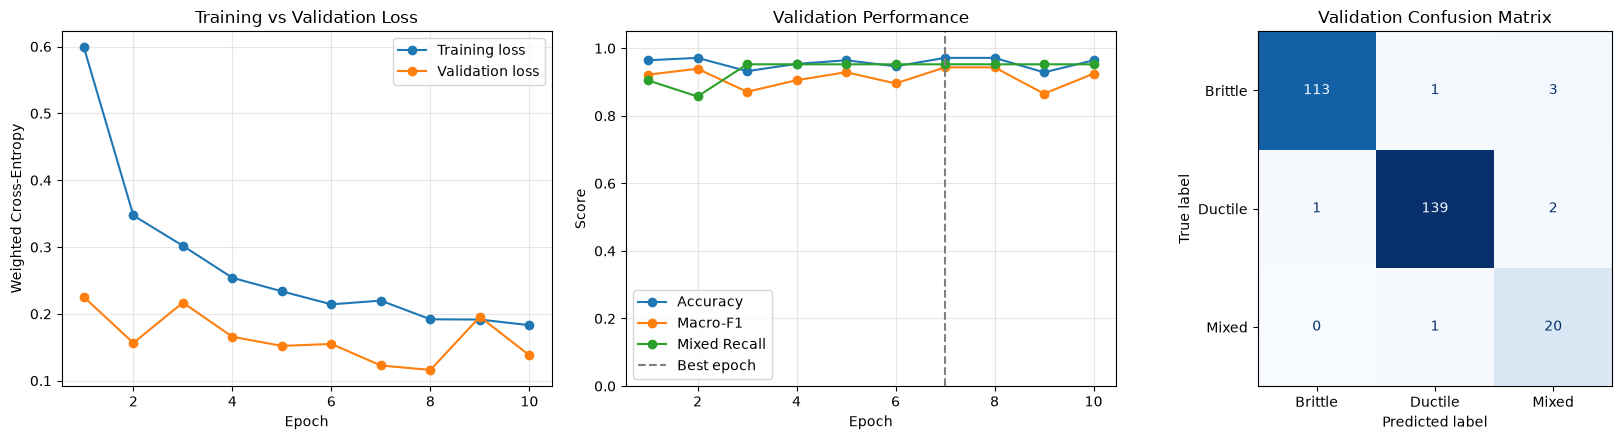

Total validation errors: 8
Plot saved to: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/resnet18_validation_analysis.png


In [11]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Evaluate the best saved model on validation data
model.eval()

val_true = []
val_pred = []

with torch.inference_mode():
    for images, labels in val_loader:

        images = images.to(DEVICE)
        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        val_true.extend(labels.tolist())
        val_pred.extend(predictions.cpu().tolist())

# 2. Print class-level performance
print("VALIDATION CLASSIFICATION REPORT\n")

print(classification_report(
    val_true,
    val_pred,
    labels=[0, 1, 2],
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

# 3. Construct confusion matrix
cm = confusion_matrix(
    val_true,
    val_pred,
    labels=[0, 1, 2]
)

# 4. Plot training curves and confusion matrix
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Plot A: Loss curves
axes[0].plot(epochs, history["train_loss"],
             label="Training loss", marker="o")
axes[0].plot(epochs, history["val_loss"],
             label="Validation loss", marker="o")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted Cross-Entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot B: Validation metrics
axes[1].plot(epochs, history["val_accuracy"],
             label="Accuracy", marker="o")
axes[1].plot(epochs, history["val_macro_f1"],
             label="Macro-F1", marker="o")
axes[1].plot(epochs, history["val_mixed_recall"],
             label="Mixed Recall", marker="o")
axes[1].axvline(best_epoch, linestyle="--",
                color="gray", label="Best epoch")
axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.3)

# Plot C: Confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)
display.plot(ax=axes[2], cmap="Blues",
             values_format="d", colorbar=False)
axes[2].set_title("Validation Confusion Matrix")

plt.tight_layout()

# 5. Save the visualization
plt.savefig(
    RESULTS_DIR / "resnet18_validation_analysis.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Total validation errors:",
      sum(t != p for t, p in zip(val_true, val_pred)))

print("Plot saved to:",
      RESULTS_DIR / "resnet18_validation_analysis.png")


Total misclassified images: 8
304_H2_03_3.png | Actual: Brittle | Predicted: Mixed | Confidence: 0.862
304_H2_03_4.png | Actual: Brittle | Predicted: Mixed | Confidence: 0.617
304_H2_04_6.png | Actual: Brittle | Predicted: Mixed | Confidence: 0.695
X65_H2_12_1.png | Actual: Brittle | Predicted: Ductile | Confidence: 0.683
316L_AR_04_7.png | Actual: Ductile | Predicted: Mixed | Confidence: 0.608
316L_AR_21_17.png | Actual: Ductile | Predicted: Mixed | Confidence: 0.768
316L_AR_21_30.png | Actual: Ductile | Predicted: Brittle | Confidence: 0.943
316L_AR_04_15.png | Actual: Mixed | Predicted: Ductile | Confidence: 0.791


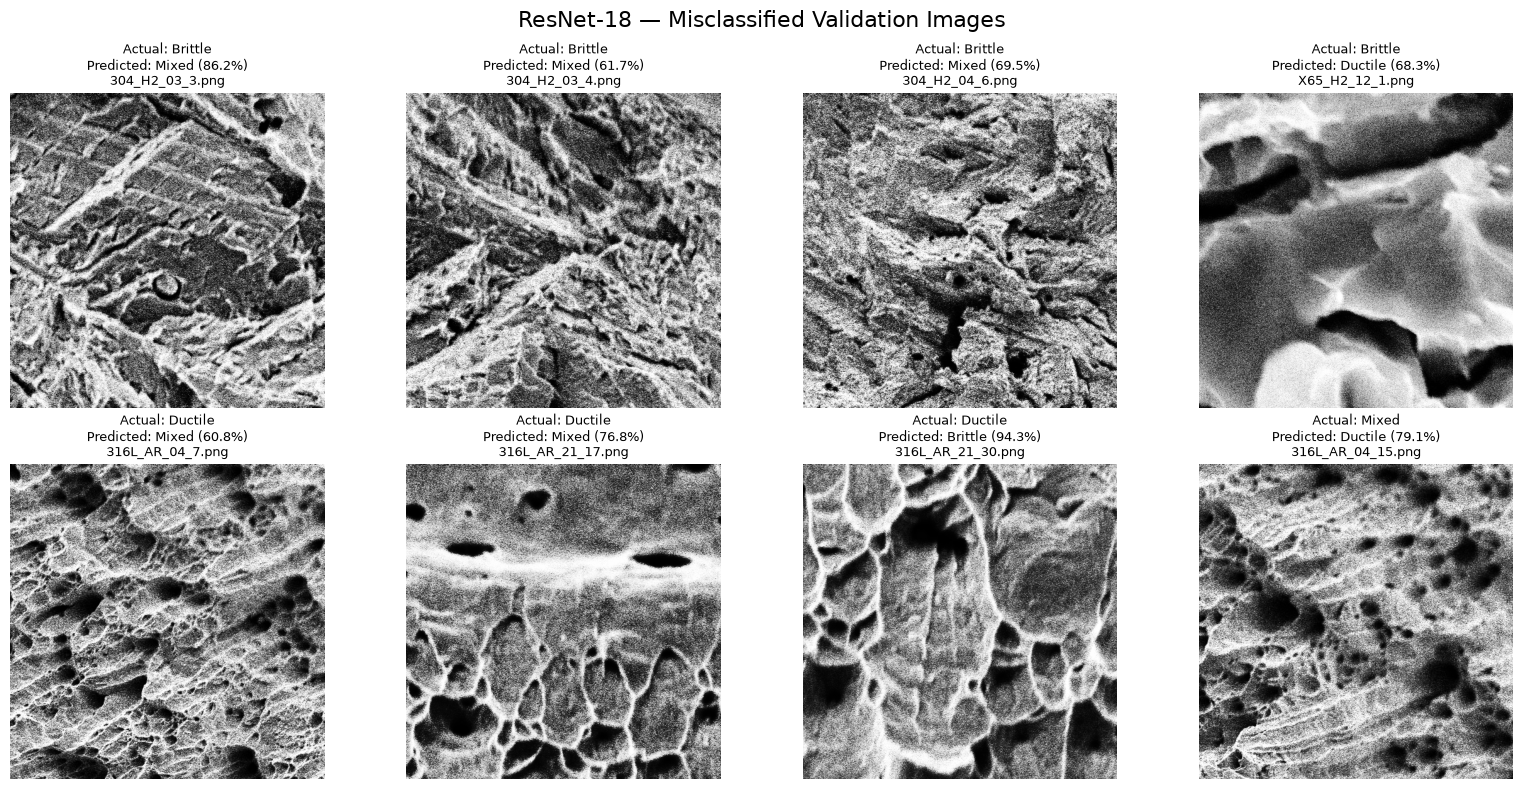

In [12]:

import math
import matplotlib.pyplot as plt
from PIL import Image

# 1. Identify misclassified validation images
error_indices = [
    i for i, (true, pred) in enumerate(
        zip(val_true, val_pred)
    )
    if true != pred
]

print("Total misclassified images:", len(error_indices))

# 2. Prepare the visualization grid
n_errors = len(error_indices)

if n_errors == 0:
    print("No validation errors to display.")

else:
    n_cols = 4
    n_rows = math.ceil(n_errors / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(16, 4 * n_rows),
        squeeze=False
    )

    model.eval()

    # 3. Inspect each incorrect prediction
    for plot_idx, data_idx in enumerate(error_indices):

        row = val_records[data_idx]

        image_path = (
            DATA_DIR / row["label"] / row["filename"]
        )

        # Load original SEM image
        with Image.open(image_path) as img:
            image = img.convert("L").copy()

        # Get normalized input tensor
        image_tensor, _ = val_dataset[data_idx]

        # Calculate prediction probabilities
        with torch.inference_mode():

            outputs = model(
                image_tensor.unsqueeze(0).to(DEVICE)
            )

            probabilities = torch.softmax(
                outputs, dim=1
            )[0].cpu()

        true_class = CLASSES[val_true[data_idx]]
        pred_class = CLASSES[val_pred[data_idx]]

        confidence = probabilities[
            val_pred[data_idx]
        ].item()

        # 4. Display image
        ax = axes.flat[plot_idx]

        ax.imshow(image, cmap="gray")

        ax.set_title(
            f"Actual: {true_class}\n"
            f"Predicted: {pred_class} ({confidence:.1%})\n"
            f"{row['filename']}",
            fontsize=9
        )

        ax.axis("off")

        print(
            f"{row['filename']} | "
            f"Actual: {true_class} | "
            f"Predicted: {pred_class} | "
            f"Confidence: {confidence:.3f}"
        )

    # Hide unused subplots
    for ax in axes.flat[n_errors:]:
        ax.axis("off")

    plt.suptitle(
        "ResNet-18 — Misclassified Validation Images",
        fontsize=16
    )

    plt.tight_layout()

    # 5. Save the result
    plt.savefig(
        RESULTS_DIR / "resnet18_errors.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


In [13]:

from collections import defaultdict, Counter

# 1. Extract metadata from filenames
def get_metadata(filename):
    parts = Path(filename).stem.split("_")

    material = parts[0]
    environment = parts[1]
    group = "_".join(parts[:-1])

    return material, environment, group

# 2. Analyze validation performance by category
def analyze_category(category_name, key_function):

    category_indices = defaultdict(list)

    for i, row in enumerate(val_records):
        category = key_function(row["filename"])
        category_indices[category].append(i)

    print(f"\nPERFORMANCE BY {category_name.upper()}")
    print("-" * 75)

    for category, indices in sorted(category_indices.items()):

        true = [val_true[i] for i in indices]
        pred = [val_pred[i] for i in indices]

        correct = sum(t == p for t, p in zip(true, pred))
        accuracy = correct / len(indices)

        mixed_total = sum(t == 2 for t in true)
        mixed_correct = sum(
            t == 2 and p == 2
            for t, p in zip(true, pred)
        )

        print(
            f"{category:12s} | "
            f"Images: {len(indices):3d} | "
            f"Accuracy: {accuracy:.3f} | "
            f"Errors: {len(indices)-correct:2d} | "
            f"Mixed: {mixed_correct}/{mixed_total}"
        )

# 3. Analyze by steel type
analyze_category(
    "Material",
    lambda filename: get_metadata(filename)[0]
)

# 4. Analyze by testing environment
analyze_category(
    "Environment",
    lambda filename: get_metadata(filename)[1]
)

# 5. Identify groups containing errors
error_groups = defaultdict(list)

for i in error_indices:
    filename = val_records[i]["filename"]
    group = get_metadata(filename)[2]
    error_groups[group].append(filename)

print("\nGROUPS CONTAINING ERRORS")
print("-" * 75)

for group, filenames in sorted(
    error_groups.items(),
    key=lambda x: len(x[1]),
    reverse=True
):
    print(f"{group}: {len(filenames)} errors")
    for filename in filenames:
        print("  ", filename)



PERFORMANCE BY MATERIAL
---------------------------------------------------------------------------
100Cr6       | Images:  30 | Accuracy: 1.000 | Errors:  0 | Mixed: 0/0
304          | Images:  49 | Accuracy: 0.939 | Errors:  3 | Mixed: 7/7
316L         | Images:  58 | Accuracy: 0.931 | Errors:  4 | Mixed: 0/1
X65          | Images:  52 | Accuracy: 0.981 | Errors:  1 | Mixed: 0/0
mX65         | Images:  91 | Accuracy: 1.000 | Errors:  0 | Mixed: 13/13

PERFORMANCE BY ENVIRONMENT
---------------------------------------------------------------------------
AIR          | Images:  15 | Accuracy: 1.000 | Errors:  0 | Mixed: 0/0
AR           | Images: 111 | Accuracy: 0.964 | Errors:  4 | Mixed: 0/1
H2           | Images: 154 | Accuracy: 0.974 | Errors:  4 | Mixed: 20/20

GROUPS CONTAINING ERRORS
---------------------------------------------------------------------------
304_H2_03: 2 errors
   304_H2_03_3.png
   304_H2_03_4.png
316L_AR_04: 2 errors
   316L_AR_04_7.png
   316L_AR_04_15.png
3